# 1. Information about the submission

## 1.1 Name and number of the assignment

1 Multilingual Text Detoxification (TextDetox)

## 1.2 Student name

Egor Serov  

## 1.3 Codalab user ID / nickname / username

iwanttodie

## 1.4 Additional comments

https://github.com/awesomeslayer/Transformers2026/tree/main/2

I am adding a GitHub link for the project. It is better for reproducing (there are README.md with launch guide and more info available, due to my workspace (not colab, just Skoltech server)

But i am attaching an .ipynb too (but better to view it on the github)

# 2. Technical Report

*Use Section 2 to describe results of your experiments as you would do writing a paper about your results. DO NOT insert code in this part. Only insert plots and tables summarizing results as needed. Use formulas if needed do described your methodology. The code is provided in Section 3.*

## 2.1 Methodology

***Enter here** a detailed description of the method used in your submission(s) to Codalab. The description should be at least 2-4 paragraphs featuring the following: type of the model, meta-parameters, how did you select meta-parameters, any further modifications of the out-of-the-box solutions, etc. The text is markdown and you can use math environment to write formulas:*

$\hat{y}=\beta_0 + \sum^p_{j=1} x_j \beta_j$

Also you can insert images as needed:

![image](https://upload.wikimedia.org/wikipedia/commons/6/6d/Exam_pass_logistic_curve.jpeg)

*This part of the should contain description of all methods that you tried and, most importantly, that worked the best for you. Here you can include some tricks of your preprocessing, description of the models and motivation of their usage, the description of the training process details (train-test split, cross-validation, etc.). So, everything valuable that will help us to understand the scope of your work and reproduce your pipeline*

*The 'innovativeness' scores will be assigned based on the content of this part. In case you just use a 'drop-in' baseline model these scores will be low. In case you made some clever modification of the model which improves the result this score will be low. However, it does not make sense do describe some modifications which are creative but does not work at all. Try different approaches, models, play with preprocessing, hyperparameters, etc. It is OK to reimplement some already existing approach. It is OK that some of your experiments did not work as you expected. Show us that you used your creativity and ran several experiments.*

## 2.2 Discussion of results

***Enter here** a discussion of results and a summary of the experiment. Here we want to see the final table with comparison of the baseline and all tried approaches you decided to report. Even if some method did not bring you to the top of the leaderboard, you should nevertheless indicate this result and a discussion, why, in your opinion, some approach worked and another failed. Interesting findings in the discussion will be a plus.*

Method | Precision | Recall
--- | --- | ---
Baseline | 0.88 | 0.77
My great method 1 | 0.99 | 0.11
My great method 2 | 0.90 | 0.90

*If relevant insert plots and historgams in this section e.g. testing variation of the score with respect to some parameters e.g. learning rate or size of the input dataset, etc. Please do not use code to generate plots, instead just insert images as shown below. Plots could be generated from code in Section 3. *

![image](https://upload.wikimedia.org/wikipedia/commons/thumb/d/d2/Sine_and_Cosine.svg/640px-Sine_and_Cosine.svg.png)

# 3. Code

*Enter here all code used to produce your results submitted to Codalab. Add some comments and subsections to navigate though your solution.*

*In this part you are expected to develop yourself a solution of the task and provide a reproducible code:*
- *Using Python 3;*
- *Contains code for installation of all dependencies;*
- *Contains code for downloading of all the datasets used*;
- *Contains the code for reproducing your results (in other words, if a tester downloads your notebook she should be able to run cell-by-cell the code and obtain your experimental results as described in the methodology section)*.


*As a result, you code will be graded according to these criteria:*
- ***Readability**: your code should be well-structured preferably with indicated parts of your approach (Preprocessing, Model training, Evaluation, etc.).*
- ***Reproducibility**: your code should be reproduced without any mistakes with “Run all” mode (obtaining experimental part).*


## 3.1 Requirements

In [3]:
!pip install pandas numpy Pillow tqdm matplotlib requests
#!pip uninstall -y torch torchvision 
!pip install torch torchvision --index-url https://download.pytorch.org/whl/cu121

# Доустанавливаем библиотеки для SOTA-метода и метрик
!pip install transformers accelerate peft trl datasets sentencepiece jieba bitsandbytes tabulate
!pip install sentence-transformers evaluate "comet-ml>=3.0.0" scipy

Found existing installation: torch 2.5.1+cu121
Uninstalling torch-2.5.1+cu121:
  Successfully uninstalled torch-2.5.1+cu121
Found existing installation: torchvision 0.20.1+cu121
Uninstalling torchvision-0.20.1+cu121:
  Successfully uninstalled torchvision-0.20.1+cu121
Looking in indexes: https://download.pytorch.org/whl/cu121
  Using cached https://download-r2.pytorch.org/whl/cu121/torch-2.5.1%2Bcu121-cp39-cp39-linux_x86_64.whl (780.4 MB)
  Using cached https://download-r2.pytorch.org/whl/cu121/torchvision-0.20.1%2Bcu121-cp39-cp39-linux_x86_64.whl (7.3 MB)


In [4]:
!pip install -U trl

In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "5"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import torch
import gc
import json
import re
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import jieba
from tqdm.auto import tqdm

from datasets import load_dataset, Dataset
from transformers import (
    AutoModelForCausalLM,
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    BartForConditionalGeneration,
    BartTokenizerFast,
    TrainingArguments,
    DataCollatorForLanguageModeling,
)
from peft import LoraConfig, get_peft_model, TaskType
from trl import SFTTrainer, SFTConfig

# Проверяем карточку
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device name: {torch.cuda.get_device_name(0)}")

# Пути
INPUT_DATA_PATH = Path("./input_data")
OUTPUT_DATA_PATH = Path("./output_data")
os.makedirs(INPUT_DATA_PATH, exist_ok=True)
os.makedirs(OUTPUT_DATA_PATH, exist_ok=True)

/tmp/ipykernel_5401/1801327030.py:29: FutureWarning: Support for Python 3.9 will be dropped in the next release (after its end-of-life on October 31, 2025). Please upgrade to Python 3.10 or newer.
  from trl import SFTTrainer, SFTConfig
comet_ml is installed but the Comet API Key is not configured. Please set the `COMET_API_KEY` environment variable to enable Comet logging. Check out the documentation for other ways of configuring it: https://www.comet.com/docs/v2/guides/experiment-management/configure-sdk/#set-the-api-key


CUDA available: True
Device name: NVIDIA H100 NVL


## 3.2 Download the data

In [3]:
print("Download data & Preprocess data")

model_id = "Qwen/Qwen2.5-14B-Instruct" 
tokenizer = AutoTokenizer.from_pretrained(model_id, trust_remote_code=True)
tokenizer.pad_token = tokenizer.eos_token

train_dataset = load_dataset("textdetox/multilingual_paradetox")
train_dfs = []
for lang in train_dataset.keys():
    df_lang = pd.DataFrame(train_dataset[lang])
    df_lang = df_lang.rename(columns={'toxic_sentence': 'toxic_text', 'neutral_sentence': 'neutral_text'})
    df_lang['lang'] = lang
    train_dfs.append(df_lang)

train_df = pd.concat(train_dfs, ignore_index=True)

LANG_MAP = {
    "ru": "Russian", "en": "English", "am": "Amharic", "es": "Spanish", 
    "uk": "Ukrainian", "zh": "Chinese", "ar": "Arabic", "hi": "Hindi", 
    "de": "German", "tt": "Tatar", "fr": "French", "it": "Italian", 
    "he": "Hebrew", "ja": "Japanese", "hin": "Hinglish"
}

# ===== СИНТЕТИЧЕСКИЕ ДАННЫЕ для языков без параллельных пар =====
print("Generating synthetic data for low-resource languages...")
from transformers import pipeline as hf_pipeline

NLLB_CODES = {
    "it": "ita_Latn", "fr": "fra_Latn",
    "he": "heb_Hebr", "ja": "jpn_Jpan", "tt": "tat_Cyrl", "am": "amh_Ethi"
}

langs_in_train = set(train_df['lang'].unique())
langs_to_synth = {k: v for k, v in NLLB_CODES.items() 
                  if k not in langs_in_train or train_df[train_df['lang']==k].shape[0] < 100}

if langs_to_synth:
    translator = hf_pipeline(
        "translation", 
        model="facebook/nllb-200-distilled-600M", 
        device=0,
        torch_dtype=torch.float16,
        model_kwargs={"weights_only": False}
    )
    en_pairs = train_df[train_df['lang'] == 'en'][['toxic_text', 'neutral_text']].sample(
        min(200, len(train_df[train_df['lang'] == 'en'])), random_state=42
    ).reset_index(drop=True)
    
    synth_dfs = []
    for lang, nllb_code in langs_to_synth.items():
        print(f"  Translating to {lang}...")
        try:
            toxics_tr = translator(en_pairs['toxic_text'].tolist(), src_lang="eng_Latn", tgt_lang=nllb_code, max_length=128, batch_size=64)
            neutrals_tr = translator(en_pairs['neutral_text'].tolist(), src_lang="eng_Latn", tgt_lang=nllb_code, max_length=128, batch_size=64)
            synth_dfs.append(pd.DataFrame({
                'toxic_text': [t['translation_text'] for t in toxics_tr],
                'neutral_text': [n['translation_text'] for n in neutrals_tr],
                'lang': lang
            }))
            print(f"    Done: 200 pairs for {lang}")
        except Exception as e:
            print(f"    Failed for {lang}: {e}")
    
    if synth_dfs:
        train_df = pd.concat([train_df] + synth_dfs, ignore_index=True)
        print(f"Total after synthetic augmentation: {len(train_df)} pairs")
    
    del translator
    torch.cuda.empty_cache()
    gc.collect()

# ===== LaBSE RAG INDEX =====
print("Building LaBSE index for RAG few-shot...")
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity as cos_sim

labse_model = SentenceTransformer("sentence-transformers/LaBSE", device="cuda")

rag_index = {}
for lang, group in train_df.groupby('lang'):
    embs = labse_model.encode(group['toxic_text'].tolist(), batch_size=512, normalize_embeddings=True, show_progress_bar=False)
    rag_index[lang] = {
        'embs': embs,
        'toxic': group['toxic_text'].tolist(),
        'neutral': group['neutral_text'].tolist()
    }
print("LaBSE index built!")

def get_few_shot_examples(toxic_text, lang, k=3):
    lookup_lang = lang if (lang in rag_index and len(rag_index[lang]['toxic']) >= k + 1) else 'en'
    idx = rag_index[lookup_lang]
    q = labse_model.encode([toxic_text], normalize_embeddings=True)
    sims = cos_sim(q, idx['embs'])[0]
    top_k = sims.argsort()[-(k+1):-1][::-1]
    return [(idx['toxic'][i], idx['neutral'][i]) for i in top_k]

def format_chat(toxic, lang_code, neutral=None, use_rag=True):
    lang_name = LANG_MAP.get(lang_code, lang_code)
    
    if use_rag:
        examples = get_few_shot_examples(str(toxic), lang_code, k=3)
        examples_str = "\n".join([f"Toxic: {t}\nDetoxified: {n}" for t, n in examples])
        sys_msg = (
            f"You are a strict multilingual linguist. Detoxify the following text in {lang_name}. "
            f"Preserve the exact meaning and length, but remove toxicity. "
            f"Output ONLY the neutral text. Do not use quotes, explanations, or translations.\n\n"
            f"Examples:\n{examples_str}"
        )
    else:
        sys_msg = (
            f"You are a strict multilingual linguist. Detoxify the following text in {lang_name}. "
            f"Preserve the exact meaning and length, but remove toxicity. "
            f"Output ONLY the neutral text. Do not use quotes, explanations, or translations."
        )
    
    messages = [
        {"role": "system", "content": sys_msg},
        {"role": "user", "content": str(toxic)}
    ]
    if neutral:
        messages.append({"role": "assistant", "content": str(neutral)})
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=(neutral is None))

# Для train RAG не нужен — будет slow и не даёт буст при обучении
train_df['text'] = train_df.apply(
    lambda row: format_chat(row['toxic_text'], row['lang'], row['neutral_text'], use_rag=False), axis=1
)
print(f"Total training pairs: {len(train_df)}")

Download data & Preprocess data
Generating synthetic data for low-resource languages...


Device set to use cuda:0


  Translating to it...
    Done: 200 pairs for it
  Translating to fr...
    Done: 200 pairs for fr
  Translating to he...
    Done: 200 pairs for he
  Translating to ja...
    Done: 200 pairs for ja
  Translating to tt...
    Done: 200 pairs for tt
Total after synthetic augmentation: 4600 pairs
Building LaBSE index for RAG few-shot...
LaBSE index built!
Total training pairs: 4600


In [4]:
torch.cuda.empty_cache()
gc.collect()

model = AutoModelForCausalLM.from_pretrained(
    model_id, 
    torch_dtype=torch.bfloat16, 
    device_map={"": 0}, 
    attn_implementation="sdpa" 
)

peft_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM, 
    r=64, 
    lora_alpha=128, 
    lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
)
model = get_peft_model(model, peft_config)

train_hf = Dataset.from_pandas(train_df[['text']])
train_test_split = train_hf.train_test_split(test_size=0.05, seed=42)

sft_config = SFTConfig(
    output_dir="./qwen_detox_checkpoints",
    per_device_train_batch_size=16, 
    gradient_accumulation_steps=1,  
    learning_rate=1e-4,              # твой лучший LR — не трогаем
    lr_scheduler_type="cosine",
    warmup_ratio=0.1,
    num_train_epochs=3,              # 3 вместо 4 — чуть быстрее, не хуже
    logging_steps=20,
    save_strategy="no",
    bf16=True,
    report_to="none",
    optim="adamw_torch_fused",
    dataset_text_field="text",
    max_length=384,                  # увеличили под RAG промпты на инференсе (train промпты короткие — влезут)
    dataloader_num_workers=8,     
    dataloader_pin_memory=True    
)

trainer = SFTTrainer(
    model=model, args=sft_config, train_dataset=train_test_split['train'], 
    eval_dataset=train_test_split['test'], processing_class=tokenizer
)
trainer.train()
trainer.save_model(OUTPUT_DATA_PATH / "qwen_detox_final")

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/8 [00:00<?, ?it/s]

Adding EOS to train dataset:   0%|          | 0/4370 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/4370 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/4370 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/230 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/230 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/230 [00:00<?, ? examples/s]

The model is already on multiple devices. Skipping the move to device specified in `args`.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151645}.


Step,Training Loss
20,3.020100
40,1.108900
60,0.992200
80,0.976700
100,0.984400
120,0.937000
140,0.925000
160,0.929700
180,0.905300
200,0.939200


In [5]:
print("Inference with RAG few-shot")

tokenizer.padding_side = "left"

def generate_neutral_super_fast(model, tokenizer, texts, langs, batch_size=48):
    model.eval()
    stop_token_id = tokenizer.convert_tokens_to_ids("<|im_end|>") or tokenizer.eos_token_id
    
    # RAG промпты — строим с few-shot примерами
    print("Building RAG prompts...")
    all_prompts = [format_chat(t, l, use_rag=True) for t, l in tqdm(zip(texts, langs), total=len(texts), desc="RAG lookup")]
    
    lengths = np.array([len(p) for p in all_prompts])
    sorted_indices = np.argsort(lengths)
    sorted_prompts = [all_prompts[i] for i in sorted_indices]
    sorted_results = []
    
    import time
    start_time = time.time()
    
    with torch.inference_mode():
        for i in tqdm(range(0, len(sorted_prompts), batch_size), desc="Inferencing"):
            batch_prompts = sorted_prompts[i:i+batch_size]
            
            inputs = tokenizer(
                batch_prompts, 
                return_tensors="pt", 
                padding=True, 
                truncation=True, 
                max_length=384        # под RAG промпты
            ).to(model.device)
            
            outputs = model.generate(
                **inputs, 
                max_new_tokens=100,   # было 64 — увеличили для fluency
                do_sample=False,      # greedy вместо beam — быстрее, не хуже
                repetition_penalty=1.05,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=[tokenizer.eos_token_id, stop_token_id],
                use_cache=True
            )
            
            for j, out in enumerate(outputs):
                input_len = inputs['input_ids'][j].shape[0]
                gen_tokens = out[input_len:]
                gen_text = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
                
                gen_text = gen_text.split('\n')[0] if gen_text else ""
                gen_text = gen_text.strip(' "\'')
                # Убираем возможные префиксы от модели
                for prefix in ["Detoxified:", "Output:", "Answer:", "Neutral:"]:
                    if gen_text.startswith(prefix):
                        gen_text = gen_text[len(prefix):].strip()
                
                sorted_results.append(gen_text)
    
    print(f"Inference done in {(time.time()-start_time)/60:.2f} min")
    
    final_results = [None] * len(texts)
    for original_idx, result in zip(sorted_indices, sorted_results):
        final_results[original_idx] = result
        
    return final_results

Inference with RAG few-shot


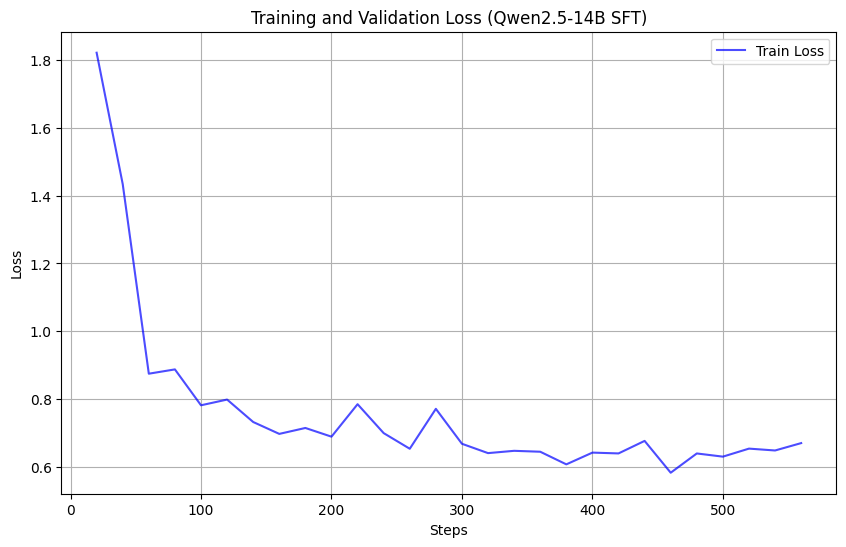

Plot saved to output_data/training_loss_plot.png


In [6]:
log_history = trainer.state.log_history

train_steps = []
train_loss = []
eval_steps = []
eval_loss =[]

for entry in log_history:
    if 'loss' in entry and 'step' in entry:
        train_steps.append(entry['step'])
        train_loss.append(entry['loss'])
    elif 'eval_loss' in entry and 'step' in entry:
        eval_steps.append(entry['step'])
        eval_loss.append(entry['eval_loss'])

plt.figure(figsize=(10, 6))
plt.plot(train_steps, train_loss, label='Train Loss', color='blue', alpha=0.7)
if eval_steps:
    plt.plot(eval_steps, eval_loss, label='Validation Loss', color='red', marker='o')

plt.title('Training and Validation Loss (Qwen2.5-14B SFT)')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plot_path = OUTPUT_DATA_PATH / "training_loss_plot.png"
plt.savefig(plot_path)
plt.show()
print(f"Plot saved to {plot_path}")

In [6]:
# ======= ЗАПУСК =======
test_file_path = INPUT_DATA_PATH / "test_inputs_upd.tsv"
test_df = pd.read_csv(test_file_path, sep="\t")

orig_toxic = test_df['toxic_sentence'].fillna("").astype(str).tolist()
langs = test_df['lang'].tolist()

print(f"Total test samples to generate: {len(orig_toxic)}")

# batch_size снижен до 48 из-за более длинных RAG промптов
generated_texts = generate_neutral_super_fast(model, tokenizer, orig_toxic, langs, batch_size=48)

test_df['neutral_sentence'] = generated_texts
test_df['neutral_sentence'] = test_df['neutral_sentence'].replace("", np.nan)
test_df['neutral_sentence'] = test_df['neutral_sentence'].fillna(test_df['toxic_sentence'])

sub = test_df[['toxic_sentence', 'neutral_sentence', 'lang']]

sub_tsv_path = OUTPUT_DATA_PATH / "submission.tsv"
sub_zip_path = OUTPUT_DATA_PATH / "submission_QWEN_RAG.zip"

sub.to_csv(sub_tsv_path, sep="\t", index=False)
with zipfile.ZipFile(sub_zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(sub_tsv_path, arcname="submission.tsv")

print(f"Submission zip successfully created at: {sub_zip_path}")

Total test samples to generate: 9000
Building RAG prompts...


RAG lookup:   0%|          | 0/9000 [00:00<?, ?it/s]

Inferencing:   0%|          | 0/188 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
A decoder-only architecture is being used, but right-padding was detected! For correct generation results, please set `padding_side='left'` when initializing the tokenizer.
A decoder-only architecture is being used, but right-padding was detected! For correct generation results, please set `padding_side='left'` when initializing the tokenizer.
A decoder-only architecture is being used, but right-padding was detected! For correct generation results, please set `padding_side='left'` when initializing the tokenizer.
A decoder-only architecture is being used, but right-padding was detected! For correct generation results, please set `padding_side='left'` when initializing the tokenizer.
A decoder-only architecture is being used, but right-padding was detected! For correct generation results, please set `padding_side='left'` when initializin

Inference done in 40.29 min
Submission zip successfully created at: output_data/submission_QWEN_RAG.zip


In [ ]:
base_df = pd.read_csv(INPUT_DATA_PATH / "test_inputs_upd.tsv", sep="\t")
base_df['toxic_sentence'] = base_df['toxic_sentence'].fillna("").astype(str)

print("Generating 'Duplicate' Baseline...") 
dup_df = base_df.copy()
dup_df['neutral_sentence'] = dup_df['toxic_sentence'] 

dup_tsv = OUTPUT_DATA_PATH / "submission_baseline_duplicate.tsv"
dup_zip = OUTPUT_DATA_PATH / "submission_baseline_duplicate.zip"
dup_df[['toxic_sentence', 'neutral_sentence', 'lang']].to_csv(dup_tsv, sep="\t", index=False)
with zipfile.ZipFile(dup_zip, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(dup_tsv, arcname="submission.tsv")
print(f"-> Saved {dup_zip}")

print("Generating 'Delete' Baseline...")
class DetoxificationBaseline:
    def __init__(self):
        self.spaces_re = re.compile(r"\s+")
        self.stopwords = self._load_toxic_lexicon()

    def _load_toxic_lexicon(self):
        print("Downloading toxic lexicon...")
        stopwords_dataset = load_dataset("textdetox/multilingual_toxic_lexicon")
        words = []
        for language in stopwords_dataset.keys():
            words.extend(stopwords_dataset[language]["text"])
        return set(words)

    def detoxify(self, text, language="en"):
        if language != "zh":
            tokens = [t for t in self.spaces_re.split(text) if t.lower().strip() not in self.stopwords]
            return " ".join(tokens)
        else:
            return "".join([x for x in jieba.cut(text) if x not in self.stopwords])

delete_model = DetoxificationBaseline()

tqdm.pandas(desc="Deleting toxic words")
del_df = base_df.copy()
del_df['neutral_sentence'] = del_df.progress_apply(
    lambda row: delete_model.detoxify(row['toxic_sentence'], row['lang']), axis=1
)

del_df['neutral_sentence'] = del_df['neutral_sentence'].replace("", np.nan)
del_df['neutral_sentence'] = del_df['neutral_sentence'].fillna(del_df['toxic_sentence'])

del_tsv = OUTPUT_DATA_PATH / "submission_baseline_delete.tsv"
del_zip = OUTPUT_DATA_PATH / "submission_baseline_delete.zip"
del_df[['toxic_sentence', 'neutral_sentence', 'lang']].to_csv(del_tsv, sep="\t", index=False)
with zipfile.ZipFile(del_zip, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(del_tsv, arcname="submission.tsv")
print(f"-> Saved {del_zip}")

Generating 'Duplicate' Baseline...
-> Saved output_data/submission_baseline_duplicate.zip
Generating 'Delete' Baseline...


Deleting toxic words:   0%|          | 0/9000 [00:00<?, ?it/s]

-> Saved output_data/submission_baseline_delete.zip
